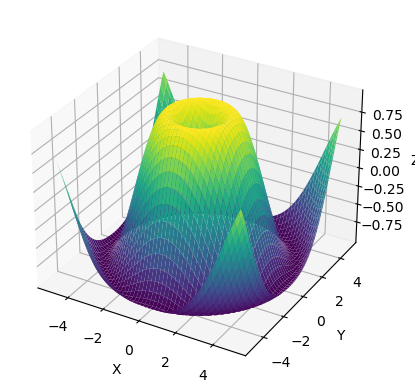

In [2]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x, y)
Z = np.sin(np.sqrt(X**2 + Y**2))

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()

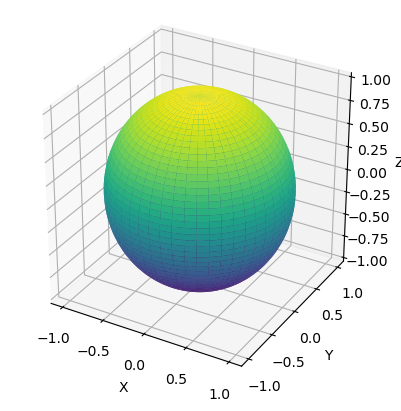

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de la esfera
r = 1
u = np.linspace(0, 2 * np.pi, 100)  # ángulo azimutal
v = np.linspace(0, np.pi, 100)      # ángulo polar

x = r * np.outer(np.cos(u), np.sin(v))
y = r * np.outer(np.sin(u), np.sin(v))
z = r * np.outer(np.ones_like(u), np.cos(v))

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(x, y, z, cmap='viridis')

ax.set_box_aspect((1, 1, 1))  # evita que se vea achatada
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()


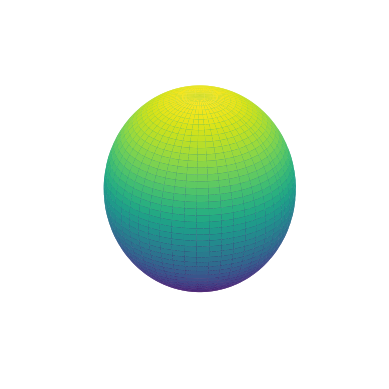

In [9]:
import numpy as np
import matplotlib.pyplot as plt

r = 10
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)

x = r * np.outer(np.cos(u), np.sin(v))
y = r * np.outer(np.sin(u), np.sin(v))
z = r * np.outer(np.ones_like(u), np.cos(v))

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(x, y, z, cmap='viridis')

ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()  # quita grilla, ejes, paneles y etiquetas
plt.show()

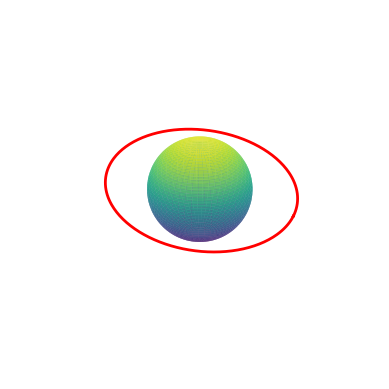

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Esfera
r = 1
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)
x = r * np.outer(np.cos(u), np.sin(v))
y = r * np.outer(np.sin(u), np.sin(v))
z = r * np.outer(np.ones_like(u), np.cos(v))

# Elipse
a, b = 2.0, 1.3          # semiejes mayor y menor
t = np.linspace(0, 2 * np.pi, 300)
ex = a * np.cos(t)
ey = b * np.sin(t)
ez = np.zeros_like(t)

# Inclinación de la elipse (rotación alrededor del eje X)
theta = np.radians(30)
ey_rot = ey * np.cos(theta) - ez * np.sin(theta)
ez_rot = ey * np.sin(theta) + ez * np.cos(theta)

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(x, y, z, cmap='viridis', alpha=0.8)
ax.plot(ex, ey_rot, ez_rot, color='red', linewidth=2)

ax.set_box_aspect((1, 1, 1))
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_zlim(-2, 2)
ax.set_axis_off()
plt.show()

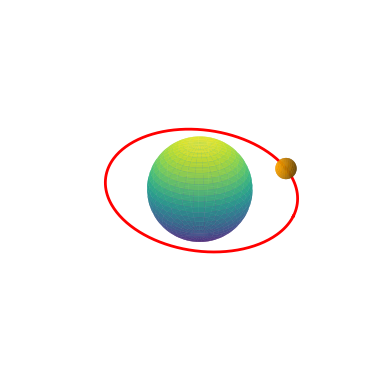

In [11]:
import numpy as np
import matplotlib.pyplot as plt

def esfera(cx, cy, cz, r, n=60):
    u = np.linspace(0, 2 * np.pi, n)
    v = np.linspace(0, np.pi, n)
    x = cx + r * np.outer(np.cos(u), np.sin(v))
    y = cy + r * np.outer(np.sin(u), np.sin(v))
    z = cz + r * np.outer(np.ones_like(u), np.cos(v))
    return x, y, z

# Elipse (órbita)
a, b = 2.0, 1.3
theta = np.radians(30)

def punto_orbita(t):
    ex = a * np.cos(t)
    ey = b * np.sin(t)
    ez = 0 * t
    # rotación alrededor del eje X
    ey_rot = ey * np.cos(theta) - ez * np.sin(theta)
    ez_rot = ey * np.sin(theta) + ez * np.cos(theta)
    return ex, ey_rot, ez_rot

t = np.linspace(0, 2 * np.pi, 300)
ox, oy, oz = punto_orbita(t)

# Posición de la pelotita sobre la órbita
t0 = np.radians(45)
px, py, pz = punto_orbita(t0)

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Esfera grande (central)
x, y, z = esfera(0, 0, 0, 1)
ax.plot_surface(x, y, z, cmap='viridis', alpha=0.8)

# Órbita
ax.plot(ox, oy, oz, color='red', linewidth=2)

# Pelotita orbitando
x2, y2, z2 = esfera(px, py, pz, 0.2)
ax.plot_surface(x2, y2, z2, color='orange')

ax.set_box_aspect((1, 1, 1))
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_zlim(-2, 2)
ax.set_axis_off()
plt.show()

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

def esfera(cx, cy, cz, r, n=30):
    u = np.linspace(0, 2 * np.pi, n)
    v = np.linspace(0, np.pi, n)
    x = cx + r * np.outer(np.cos(u), np.sin(v))
    y = cy + r * np.outer(np.sin(u), np.sin(v))
    z = cz + r * np.outer(np.ones_like(u), np.cos(v))
    return x, y, z

# Órbita
a, b = 2.0, 1.3
theta = np.radians(30)

def punto_orbita(t):
    ex = a * np.cos(t)
    ey = b * np.sin(t)
    ez = 0 * t
    ey_rot = ey * np.cos(theta) - ez * np.sin(theta)
    ez_rot = ey * np.sin(theta) + ez * np.cos(theta)
    return ex, ey_rot, ez_rot

t = np.linspace(0, 2 * np.pi, 300)
ox, oy, oz = punto_orbita(t)

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Elementos fijos
x, y, z = esfera(0, 0, 0, 1, n=60)
ax.plot_surface(x, y, z, cmap='viridis', alpha=0.8)
ax.plot(ox, oy, oz, color='red', linewidth=2)

ax.set_box_aspect((1, 1, 1))
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_zlim(-2, 2)
ax.set_axis_off()

# Pelotita: se dibuja YA desde el principio
pelota = [None]

def dibujar_pelota(t0):
    if pelota[0] is not None:
        pelota[0].remove()
    px, py, pz = punto_orbita(t0)
    x2, y2, z2 = esfera(px, py, pz, 0.2)
    pelota[0] = ax.plot_surface(x2, y2, z2, color='orange')

dibujar_pelota(0)   # posición inicial, así se ve aunque no corra la animación

def actualizar(frame):
    dibujar_pelota(2 * np.pi * frame / 120)

ani = FuncAnimation(fig, actualizar, frames=120, interval=30, blit=False)

from IPython.display import HTML

plt.close()                  # evita que se muestre también la figura estática
HTML(ani.to_jshtml())